# 🌪️ ResQTweet

Real-Time Tweet Classification for Crisis Detection

# 1. Import Modules

In [402]:
#Import Modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

# NLP
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, csr_matrix

# Modeling & evaluation
from sklearn.model_selection import train_test_split

from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

# 2. Load & Explore Dataset

In [403]:
data = pd.read_csv('/content/tweets_data.csv')

In [404]:
data.head()

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


In [405]:
data.sample(10)

,id,keyword,location,text,target
900,1302,bloody,Singapore,Damn bloody hot,0
563,814,battle,NaN,A young German stormtrooper engaged in the Bat...,1
2533,3637,desolation,NaN,Hey girl you must be Toe Hobbit: Part Two: ghe...,0
2421,3481,derailed,NaN,Oh wait I expected to go a totally different r...,0
3488,4985,explosion,On the toilet having a dump,@lordRsBiscuits That's always good for a prett...,1
982,1421,body%20bag,NaN,Nuu that FAM?? fwt I'm Leave You In a Body bag??,0
726,1049,bleeding,NaN,Keep thinking about it until I stepped on a br...,0
3142,4516,emergency,"Based out of Portland, Oregon",@newyorkcity for the #international emergency ...,0
5518,7872,quarantined,China,Top link: Reddit's new content policy goes int...,0
191,270,ambulance,Karachi,Twelve feared killed in Pakistani air ambulanc...,1


In [406]:
data.shape

(7613, 5)

In [407]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7613 entries, 0 to 7612
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        7613 non-null   int64 
 1   keyword   7552 non-null   object
 2   location  5080 non-null   object
 3   text      7613 non-null   object
 4   target    7613 non-null   int64 
dtypes: int64(2), object(3)
memory usage: 297.5+ KB


In [408]:
data.describe()

,id,target
count,7613.000000,7613.00000
mean,5441.934848,0.42966
std,3137.116090,0.49506
min,1.000000,0.00000
25%,2734.000000,0.00000
50%,5408.000000,0.00000
75%,8146.000000,1.00000
max,10873.000000,1.00000


In [409]:
data.columns

Index(['id', 'keyword', 'location', 'text', 'target'], dtype='object')

In [410]:
print(data['target'].value_counts())

target
0    4342
1    3271
Name: count, dtype: int64


# 3. Data Cleaning & Preprocessing

In [411]:
data.isnull().sum()

,0
id,0
keyword,61
location,2533
text,0
target,0


In [412]:
def clean_text(text):
    if pd.isna(text):  # handle NaN
        return ""

    # 1. Decode URL encodings (%20, %2F etc.)
    text = re.sub(r'%[0-9A-Fa-f]{2}', ' ', text)

    # 2. Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # 3. Remove mentions (@username)
    text = re.sub(r'@\w+', '', text)

    # 4. Remove hashtags (#word → word)
    text = re.sub(r'#', '', text)

    # 5. Remove non-alphabetic characters (keeps only letters & spaces)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)

    # 6. Lowercase
    text = text.lower()

    # 7. Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


In [413]:
# List of text columns to clean
text_columns = ['keyword', 'location', 'text']

for col in text_columns:
    data[col + '_clean'] = data[col].apply(clean_text)
    data[col + '_clean'] = data[col].apply(clean_text)



In [414]:
data.sample(5)

,id,keyword,location,text,target,keyword_clean,location_clean,text_clean
6871,9850,trauma,Minneapolis/St. Paul,Simmering beneath #NHL good times the league's...,0,trauma,minneapolis st paul,simmering beneath nhl good times the league s ...
7070,10126,upheaval,NaN,Tt kettlebell upheaval blueprint over chris lo...,0,upheaval,,tt kettlebell upheaval blueprint over chris lo...
2454,3522,derailment,India,Madhya Pradesh Train Derailment: Village Youth...,1,derailment,india,madhya pradesh train derailment village youth ...
3100,4450,electrocuted,NaN,'Hey bitch blow me' uh no. Stick your dick in ...,0,electrocuted,,hey bitch blow me uh no stick your dick in som...
6132,8750,siren,NaN,Lol '@j2bone: *cousin ' @Foxy__Siren: Coursing...,0,siren,,lol cousin coursing now they are causing di ma...


We decided to drop the location column because it contained highly noisy, inconsistent, and often irrelevant information. Since a large proportion of rows were missing or ambiguous (e.g., ‘nyc nj’, ‘we are global’), and given the time constraints of the hackathon, we focused on text and keyword which provide stronger, more reliable features for disaster classification.

In [415]:
data_cleaned = data[['id', 'keyword_clean', 'text_clean', 'target']]


In [416]:
data_cleaned.sample(5)

,id,keyword_clean,text_clean,target
783,1134,blight,blight,0
1663,2400,collapsed,petition heartless owner that whipped horse un...,1
4022,5713,forest fire,i added a video to a playlist ori and the bind...,1
6866,9838,trauma,esteemed journalist recalls tragic effects of ...,1
1425,2057,casualties,afghanistan sharp rise in women and children c...,1


In [417]:
data_cleaned.isnull().sum()

,0
id,0
keyword_clean,0
text_clean,0
target,0


In [418]:
data_cleaned.loc[:, 'has_keyword'] = (data_cleaned['keyword_clean'].str.len() > 0).astype(int)
data_cleaned.sample()

/tmp/ipython-input-677578473.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_cleaned.loc[:, 'has_keyword'] = (data_cleaned['keyword_clean'].str.len() > 0).astype(int)


,id,keyword_clean,text_clean,target,has_keyword
432,625,arsonist,zodiac girl feat trey dupree produced by spark...,0,1


# 4. Train-Test-SPLIT

In [419]:
y = data_cleaned['target']
x = data_cleaned.drop('target', axis=1)

In [420]:
x_train, x_val, y_train, y_val = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# 5. Natural Language Processing (NLP)

In [421]:
# Text Column

tfidf_text = TfidfVectorizer(
    max_features=6000,      # keep top 6k features to control size
    ngram_range=(1,2),      # unigrams + bigrams ("fire", "suicide bomb")
    min_df=2,               # ignore words seen only once (reduces noise)
    sublinear_tf=True       # use 1+log(tf) so very frequent words don’t dominate
)
x_text_train = tfidf_text.fit_transform(x_train['text_clean'])
x_text_val   = tfidf_text.transform(x_val['text_clean'])


In [422]:
# Keyword Column

tfidf_kw = TfidfVectorizer()  # defaults: unigrams, no cap
x_kw_train = tfidf_kw.fit_transform(x_train['keyword_clean'])
x_kw_val   = tfidf_kw.transform(x_val['keyword_clean'])


In [423]:
x_train_vec = hstack([
    x_text_train,               # (n_train, V_text)
    x_kw_train,                 # (n_train, V_kw)
    csr_matrix(x_train['has_keyword'].values).reshape(-1, 1)  # (n_train, 1)
])
x_val_vec   = hstack([
    x_text_val,
    x_kw_val,
    csr_matrix(x_val['has_keyword'].values).reshape(-1, 1)
])


In [424]:
x_train_vec.shape, x_val_vec.shape, y_train.shape, y_val.shape


((6090, 6230), (1523, 6230), (6090,), (1523,))

| Set            | Shape of Features | Shape of Labels | Meaning                                                                                  |
| -------------- | ----------------- | --------------- | ---------------------------------------------------------------------------------------- |
| **Train**      | (6090, 6230)      | (6090,)         | 6,090 tweets, each represented by 6,230 features (words, bigrams, keyword TF-IDF, flag). |
| **Validation** | (1523, 6230)      | (1523,)         | 1,523 tweets, same 6,230 features, used for evaluation.                                  |

**Key Takeaway:**

- We have ~6k training examples and ~1.5k validation examples.

- Each example is a 6,230-dimensional sparse vector.

- This high dimensionality is expected for text, since each unique word/bigram adds a feature.

In [425]:
print(f"Density: {x_train_vec.nnz / (x_train_vec.shape[0] * x_train_vec.shape[1]):.6f}")


Density: 0.002575


| Metric      | Value              | Meaning                                                                          |
| ----------- | ------------------ | -------------------------------------------------------------------------------- |
| **Density** | 0.002575 (\~0.25%) | On average, only **0.25% of the 6,230 features** are non-zero in a tweet vector. |


**Key Takeaway:**

- Each tweet activates only ~15–20 features out of 6,230 (since tweets are short).

- ~99.75% of entries are zero, which is normal in NLP.

- Sparse matrices are designed to handle this efficiently — no wasted memory or computation.

target
0    3473
1    2617
Name: count, dtype: int64


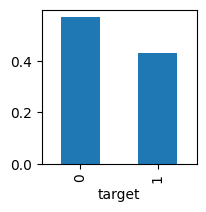

In [426]:
plt.figure(figsize=(2,2))
y_train.value_counts(normalize=True).plot(kind='bar')
print(y_train.value_counts())

# 6. Model Creation & Evaluation

In [427]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

models = {
    "MultinomialNB": MultinomialNB(),
    "ComplementNB": ComplementNB(),
    "LogisticRegression": LogisticRegression(
        max_iter=2000, solver='saga', C=2.0, n_jobs=-1, random_state=42
    )
}

results = {}

for name, model in models.items():
    model.fit(x_train_vec, y_train)
    y_pred = model.predict(x_val_vec)

    # Store results in dictionary
    results[name] = {
        "accuracy_%": round(accuracy_score(y_val, y_pred) * 100, 2),
        "confusion_matrix": confusion_matrix(y_val, y_pred),
        "classification_report": classification_report(y_val, y_pred, digits=3)
    }

# Print neatly for all models
for name, info in results.items():
    print(f"\n--- {name} ---")
    print("Accuracy: ", info["accuracy_%"], "%")
    print("Confusion Matrix:\n", info["confusion_matrix"])
    print("Classification Report:\n", info["classification_report"])



--- MultinomialNB ---
Accuracy:  81.29 %
Confusion Matrix:
 [[762 107]
 [178 476]]
Classification Report:
               precision    recall  f1-score   support

           0      0.811     0.877     0.842       869
           1      0.816     0.728     0.770       654

    accuracy                          0.813      1523
   macro avg      0.814     0.802     0.806      1523
weighted avg      0.813     0.813     0.811      1523


--- ComplementNB ---
Accuracy:  80.7 %
Confusion Matrix:
 [[733 136]
 [158 496]]
Classification Report:
               precision    recall  f1-score   support

           0      0.823     0.843     0.833       869
           1      0.785     0.758     0.771       654

    accuracy                          0.807      1523
   macro avg      0.804     0.801     0.802      1523
weighted avg      0.806     0.807     0.807      1523


--- LogisticRegression ---
Accuracy:  81.48 %
Confusion Matrix:
 [[749 120]
 [162 492]]
Classification Report:
               preci

# 7. Interpretation

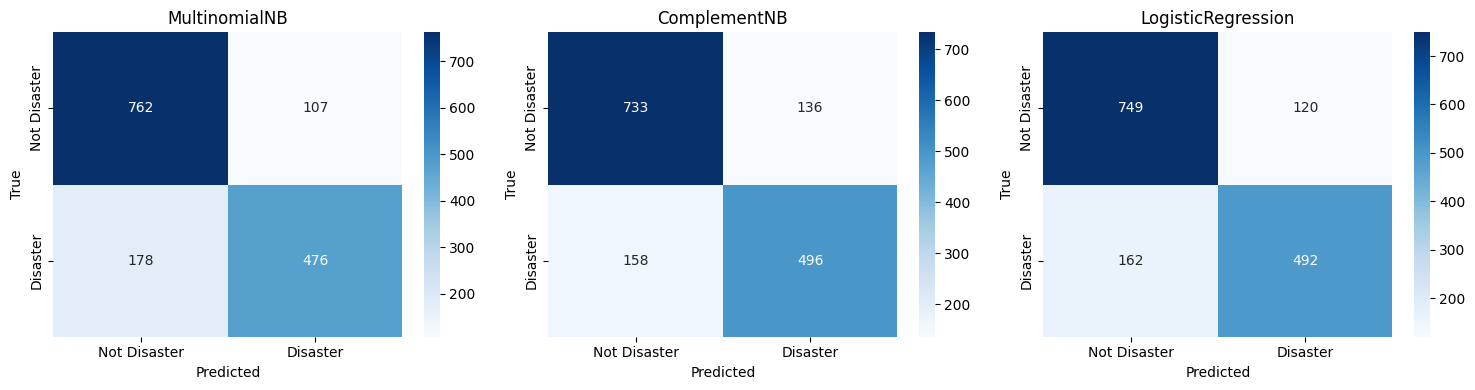

In [428]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))  # 1 row, 3 cols

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(x_val_vec)
    cm = confusion_matrix(y_val, y_pred)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Not Disaster','Disaster'],
                yticklabels=['Not Disaster','Disaster'],
                ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.tight_layout()
plt.show()


| Model              | Accuracy (%) | Precision (Disaster) | Recall (Disaster) | F1-score (Disaster) |
| ------------------ | ------------ | -------------------- | ----------------- | ------------------- |
| MultinomialNB      | 81.29        | 0.816                | 0.728             | 0.770               |
| ComplementNB       | 80.70        | 0.785                | 0.758             | 0.771               |
| LogisticRegression | 81.48        | 0.804                | 0.752             | 0.777               |


**Observations:**

- LogisticRegression gives the best overall accuracy and F1-score.

- MultinomialNB has slightly higher precision but lower recall → may miss some disaster tweets.

- ComplementNB catches more disasters (higher recall) but has slightly lower precision.

# Best Model

In [429]:
best_model = LogisticRegression(max_iter=2000, solver='saga', C=2.0, n_jobs=-1, random_state=42)
best_model.fit(x_train_vec, y_train)

LogisticRegression(C=2.0, max_iter=2000, n_jobs=-1, random_state=42,
                   solver='saga')

# 8. Building Alert System

In [430]:
try:
    from transformers import pipeline
    summarizer = pipeline("summarization", model="sshleifer/distilbart-cnn-12-6")
    HAS_HF = True
except Exception as e:
    print("Summarizer not available, will use fallback. Error:", e)
    HAS_HF = False


Device set to use cpu


In [431]:
def summarize_tweet(txt: str) -> str:
    words = txt.strip().split()
    if len(words) <= 12 or not HAS_HF:  # adjust threshold
        return (txt[:140] + '...') if len(txt) > 140 else txt
    try:
        out = summarizer(txt, max_length=10, min_length=5, do_sample=False)
        return out[0]['summary_text']
    except Exception:
        return (txt[:140] + '...') if len(txt) > 140 else txt


In [432]:
def predict_label(raw_text: str) -> int:
    cleaned = clean_text(raw_text)   # your cleaning function
    x_text = tfidf_text.transform([cleaned])
    x_kw   = tfidf_kw.transform([""])  # no keyword in ad-hoc input
    x_flag = csr_matrix([[0]])         # no keyword flag
    x = hstack([x_text, x_kw, x_flag])
    return int(best_model.predict(x)[0])


In [433]:
def disaster_alert_system(raw_text: str) -> str:
    label = predict_label(raw_text)
    if label == 1:
        alert = summarize_tweet(raw_text)
        return f"🚨 DISASTER ALERT: {alert}"
    else:
        return "✅ No disaster detected."


# Sample Input


In [434]:
disaster_alert_system("Earthquake of 6.1 magnitude hits California.")

'🚨 DISASTER ALERT: Earthquake of 6.1 magnitude hits California.'

In [435]:
disaster_alert_system("Happy birthday to my dog 🎂🐶")

'✅ No disaster detected.'

In [436]:
disaster_alert_system("Floods have destroyed several villages in Bangladesh.")

'🚨 DISASTER ALERT: Floods have destroyed several villages in Bangladesh.'

In [439]:
disaster_alert_system("Fireworks in the city tonight, what a show!")

'✅ No disaster detected.'

In [437]:
disaster_alert_system("Explosion at chemical plant in Houston, authorities evacuating nearby areas.")

'🚨 DISASTER ALERT: Explosion at chemical plant in Houston, authorities evacuating nearby areas.'

In [440]:
disaster_alert_system("Huge flood of messages in my inbox 😂")

'✅ No disaster detected.'

In [438]:
disaster_alert_system("The stock market crashed today, losing billions.")

'✅ No disaster detected.'